In [60]:
import pandas as pd
import matplotlib.pyplot as plt

In [61]:
df = pd.read_csv("data/raw/hillstrom.csv")

In [62]:
#1. Dataset dimensions
print("Dataser shape:",df.shape)

# 2. Data types
print("\nData type")
print(df.dtypes)

#3. Missing Values
print("\n Missing values")
print(df.isnull().sum())

# 4. Duplicate rows
print("\n Duplicate rows")
print(df.duplicated().sum())

# 5. Experiment groups
print("\n Experiment groups")
print(df["segment"].value_counts())
# 6. Numerical statistics
print("\n Descriptive statistics")
print(df.describe())


Dataser shape: (64000, 12)

Data type
recency              int64
history_segment        str
history            float64
mens                 int64
womens               int64
zip_code               str
newbie               int64
channel                str
segment                str
visit                int64
conversion           int64
spend              float64
dtype: object

 Missing values
recency            0
history_segment    0
history            0
mens               0
womens             0
zip_code           0
newbie             0
channel            0
segment            0
visit              0
conversion         0
spend              0
dtype: int64

 Duplicate rows
6562

 Experiment groups
segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
Name: count, dtype: int64

 Descriptive statistics
            recency       history          mens        womens        newbie  \
count  64000.000000  64000.000000  64000.000000  64000.000000  64000.000000   
mean       5.7

In [63]:
# Complete data quality summary
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_pct": df.isna().mean() * 100,
    "unique_values": df.nunique()
})

display(quality)

# Experiment allocation
display(
    df["segment"].value_counts().to_frame("customers")
)

# Outcome distribution
display (
    df[[
        "visit", "conversion", "spend"
    ]]
    .describe()
)

,dtype,missing,missing_pct,unique_values
recency,int64,0,0.0,12
history_segment,str,0,0.0,7
history,float64,0,0.0,34833
mens,int64,0,0.0,2
womens,int64,0,0.0,2
zip_code,str,0,0.0,3
newbie,int64,0,0.0,2
channel,str,0,0.0,3
segment,str,0,0.0,3
visit,int64,0,0.0,2


,customers
segment,
Womens E-Mail,21387
Mens E-Mail,21307
No E-Mail,21306


,visit,conversion,spend
count,64000.000000,64000.000000,64000.000000
mean,0.146781,0.009031,1.050908
std,0.353890,0.094604,15.036448
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000
max,1.000000,1.000000,499.000000


In [64]:
campaign_kpi = (
    df.groupby("segment").agg(
        customers = ("visit","size"),
        visitors = ("visit","sum"),
        conversions = ("conversion", "sum"),
        total_spend = ("spend","sum")
    )
    .reset_index()
)

campaign_kpi["visit_rate"] = (campaign_kpi["visitors"]/ campaign_kpi["customers"])

campaign_kpi["conversion_rate"] = (campaign_kpi["conversions"]/ campaign_kpi["customers"])

campaign_kpi["revenue_per_customer"] = (campaign_kpi["total_spend"]/ campaign_kpi["customers"])

display(campaign_kpi.round(4))

,segment,customers,visitors,conversions,total_spend,visit_rate,conversion_rate,revenue_per_customer
0,Mens E-Mail,21307,3894,267,30311.69,0.1828,0.0125,1.4226
1,No E-Mail,21306,2262,122,13908.33,0.1062,0.0057,0.6528
2,Womens E-Mail,21387,3238,189,23038.11,0.1514,0.0088,1.0772


In [65]:
total_customers = len(df)

zero_spend = (df["spend"] == 0).sum()
positive_spend = (df["spend"] > 0).sum()

print("Total Customers:", total_customers)
print("Zero Spend:", zero_spend)
print("Positive Spend:", positive_spend)

print("Zero Spend Rate:", round(zero_spend / total_customers * 100, 2), "%")
print("Positive Spend Rate:", round(positive_spend / total_customers * 100, 2), "%")

Total Customers: 64000
Zero Spend: 63422
Positive Spend: 578
Zero Spend Rate: 99.1 %
Positive Spend Rate: 0.9 %


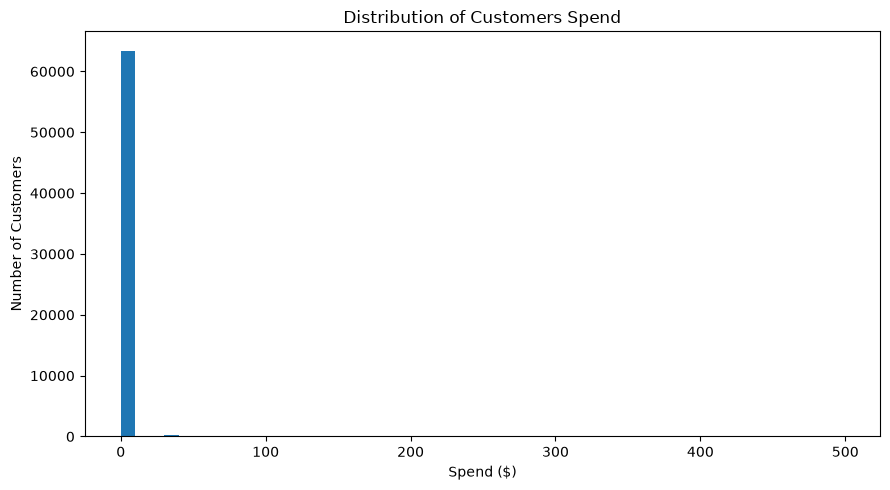

In [66]:
plt.figure(figsize = (9,5))
plt.hist(df["spend"],bins = 50)

plt.title("Distribution of Customers Spend")
plt.xlabel("Spend ($)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [67]:
total_customers = len(df)

zero_spend = (df["spend"] == 0).sum()
positive_spend = (df["spend"] > 0).sum()

print("Total Customers:", total_customers)
print("Zero Spend:", zero_spend)
print("Positive Spend:", positive_spend)

print("Zero Spend Rate:", round(zero_spend / total_customers * 100, 2), "%")
print("Positive Spend Rate:", round(positive_spend / total_customers * 100, 2), "%")

Total Customers: 64000
Zero Spend: 63422
Positive Spend: 578
Zero Spend Rate: 99.1 %
Positive Spend Rate: 0.9 %


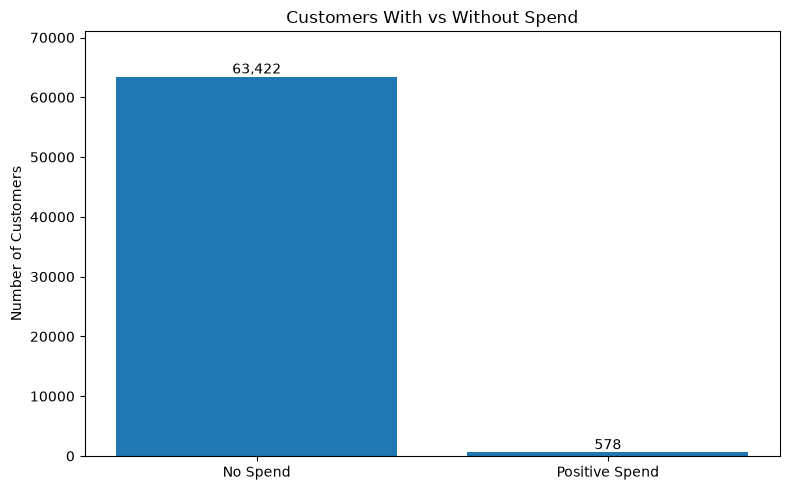

In [68]:
spend_status = df["spend"].gt(0).map({
    False: "No Spend",
    True: "Positive Spend"
})

counts = spend_status.value_counts().reindex(
    ["No Spend", "Positive Spend"]
)

plt.figure(figsize=(8, 5))
bars = plt.bar(counts.index, counts.values)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center",
        va="bottom"
    )

plt.title("Customers With vs Without Spend")
plt.ylabel("Number of Customers")
plt.ylim(0, counts.max() * 1.12)
plt.tight_layout()
plt.show()

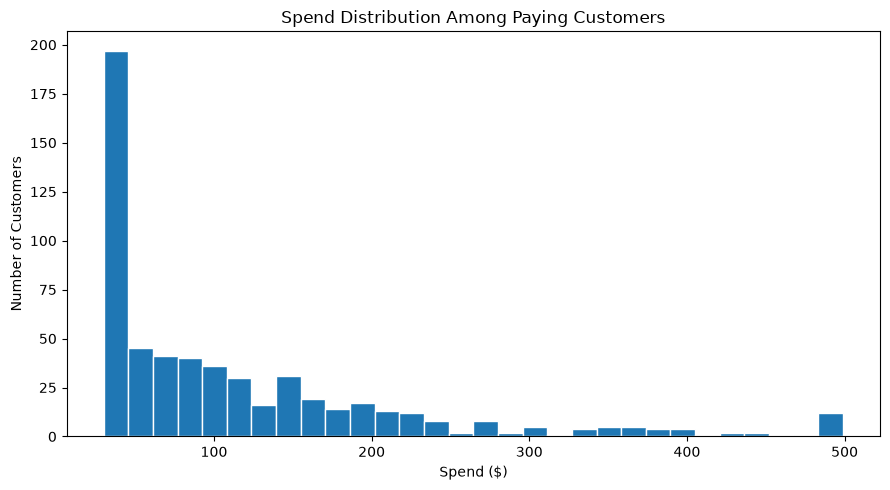

In [69]:
positive_spend = df.loc[df["spend"] > 0, "spend"]

plt.figure(figsize=(9, 5))

plt.hist(positive_spend, bins=30, edgecolor="white")

plt.title("Spend Distribution Among Paying Customers")
plt.xlabel("Spend ($)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [70]:
print("All customers:")
display(df["spend"].describe())

print("Paying customers only:")
display(positive_spend.describe())

print("Skewness:", positive_spend.skew())

All customers:


count    64000.000000
mean         1.050908
std         15.036448
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        499.000000
Name: spend, dtype: float64

Paying customers only:


count    578.000000
mean     116.363547
std      107.871537
min       29.990000
25%       32.272500
50%       80.795000
75%      153.350000
max      499.000000
Name: spend, dtype: float64

Skewness: 1.7609781095675943


The spend distribution is highly concentrated near zero, with a small proportion of customers generating positive spend. To understand customer spending behaviour more clearly, we should analyse both the proportion of paying customers and the distribution of spend among those customers.

In [71]:
balance = (
    df.groupby("segment")
    .agg(
        customers=("segment", "size"),
        avg_recency=("recency", "mean"),
        avg_history=("history", "mean"),
        newbie_rate=("newbie", "mean")
    )
)

balance["newbie_rate"] *= 100

display(balance.round(2))

,customers,avg_recency,avg_history,newbie_rate
segment,,,,
Mens E-Mail,21307,5.77,242.84,50.15
No E-Mail,21306,5.75,240.88,50.20
Womens E-Mail,21387,5.77,242.54,50.32


# Step 3 – CRM Campaign Performance

In [72]:
campaign_kpi = (
    df.groupby("segment")
    .agg(
        customers=("conversion", "size"),
        visitors=("visit", "sum"),
        conversions=("conversion", "sum"),
        total_spend=("spend", "sum")
    )
    .reset_index()
)

campaign_kpi["visit_rate"] = (
    campaign_kpi["visitors"] / campaign_kpi["customers"] * 100
)

campaign_kpi["conversion_rate"] = (
    campaign_kpi["conversions"] / campaign_kpi["customers"] * 100
)

campaign_kpi["revenue_per_customer"] = (
    campaign_kpi["total_spend"] / campaign_kpi["customers"]
)

display(campaign_kpi.round(2))

,segment,customers,visitors,conversions,total_spend,visit_rate,conversion_rate,revenue_per_customer
0,Mens E-Mail,21307,3894,267,30311.69,18.28,1.25,1.42
1,No E-Mail,21306,2262,122,13908.33,10.62,0.57,0.65
2,Womens E-Mail,21387,3238,189,23038.11,15.14,0.88,1.08


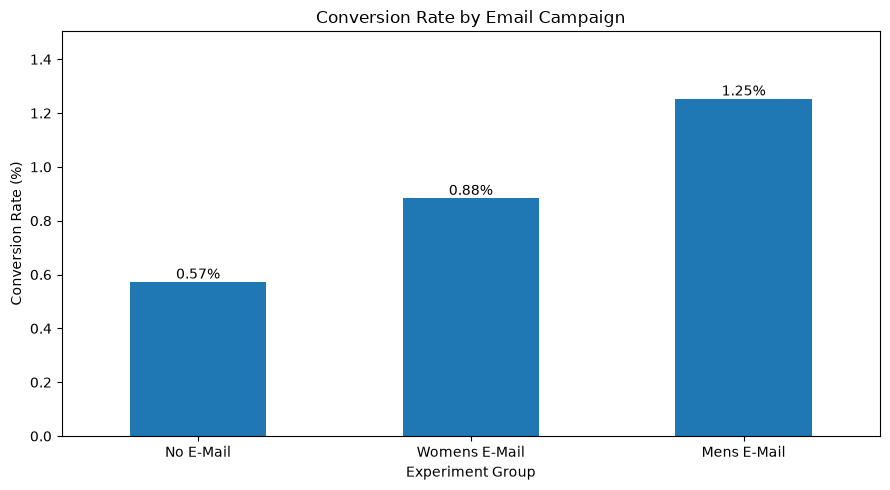

In [73]:

order = ["No E-Mail", "Womens E-Mail", "Mens E-Mail"]
plot_df = campaign_kpi.set_index("segment").loc[order]

ax = plot_df["conversion_rate"].plot(
    kind="bar",
    figsize=(9, 5)
)

for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.2f}%",
        (bar.get_x() + bar.get_width()/2, bar.get_height()),
        ha="center",
        va="bottom"
    )

plt.title("Conversion Rate by Email Campaign")
plt.ylabel("Conversion Rate (%)")
plt.xlabel("Experiment Group")
plt.xticks(rotation=0)
plt.ylim(0, plot_df["conversion_rate"].max() * 1.2)
plt.tight_layout()
plt.show()


Conversion Lift – So sánh với Control

Để đo mức chênh lệch so với nhóm không nhận email:

• (CVR_{control}) (Conversion Rate of Control): Tỷ lệ chuyển đổi của nhóm đối chứng (nhóm giữ nguyên giao diện/tính năng cũ, phiên bản gốc A).

• (CVR_{treatment}) (Conversion Rate of Treatment): Tỷ lệ chuyển đổi của nhóm thử nghiệm (nhóm áp dụng giao diện/tính năng mới đổi, phiên bản B).

• Relative Lift (Tăng trưởng tương đối): Tỷ lệ phần trăm thay đổi (tăng hoặc giảm) của nhóm thử nghiệm so với nhóm đối chứng.


Sau khi tính toán, kết quả của Relative Lift sẽ cho bạn biết:

• Nếu kết quả Dương (>0): Phiên bản mới hoạt động tốt hơn phiên bản cũ. Ví dụ: Kết quả là +15% nghĩa là phiên bản mới giúp tăng 15% tỷ lệ chuyển đổi so với bản cũ.

• Nếu kết quả Âm (<0): Phiên bản mới hoạt động kém hơn phiên bản cũ. Ví dụ: Kết quả là -5% nghĩa là tỷ lệ chuyển đổi bị giảm đi 5%.

In [74]:
control_rate = campaign_kpi.loc[
    campaign_kpi["segment"] == "No E-Mail",
    "conversion_rate"
].iloc[0]

campaign_kpi["conversion_lift_pct"] = (
    (campaign_kpi["conversion_rate"] / control_rate - 1)
    * 100
)

display(
    campaign_kpi[
        ["segment", "conversion_rate", "conversion_lift_pct"]
    ].round(2)
)

,segment,conversion_rate,conversion_lift_pct
0,Mens E-Mail,1.25,118.84
1,No E-Mail,0.57,0.00
2,Womens E-Mail,0.88,54.33


The Men's Email campaign achieved the highest conversion rate at 1.25%, compared with 0.57% for the control group. This represents an approximately 119% relative increase in conversion rate. Statistical testing is required to confirm the significance of the result.

# Which customer segments respond best to our email campaigns?"

In [75]:
df["recency_group"] = pd.cut(
    df["recency"],
    bins=[-1, 3, 6, 9, float("inf")],
    labels=[
        "0-3 Months",
        "4-6 Months",
        "7-9 Months",
        "10+ Months"
    ]
)

display(df["recency_group"].value_counts().sort_index())

recency_group
0-3 Months    22393
4-6 Months    14192
7-9 Months    14014
10+ Months    13401
Name: count, dtype: int64

In [76]:
recency_kpi = (
    df.groupby("recency_group", observed=True)
    .agg(
        customers=("conversion", "size"),
        visitors=("visit", "sum"),
        conversions=("conversion", "sum"),
        total_spend=("spend", "sum")
    )
    .reset_index()
)

recency_kpi["visit_rate"] = (
    recency_kpi["visitors"] /
    recency_kpi["customers"] * 100
)

recency_kpi["conversion_rate"] = (
    recency_kpi["conversions"] /
    recency_kpi["customers"] * 100
)

recency_kpi["revenue_per_customer"] = (
    recency_kpi["total_spend"] /
    recency_kpi["customers"]
)

display(recency_kpi.round(2))

,recency_group,customers,visitors,conversions,total_spend,visit_rate,conversion_rate,revenue_per_customer
0,0-3 Months,22393,4050,277,31637.92,18.09,1.24,1.41
1,4-6 Months,14192,2046,113,12813.59,14.42,0.80,0.90
2,7-9 Months,14014,1727,100,12293.57,12.32,0.71,0.88
3,10+ Months,13401,1571,88,10513.05,11.72,0.66,0.78


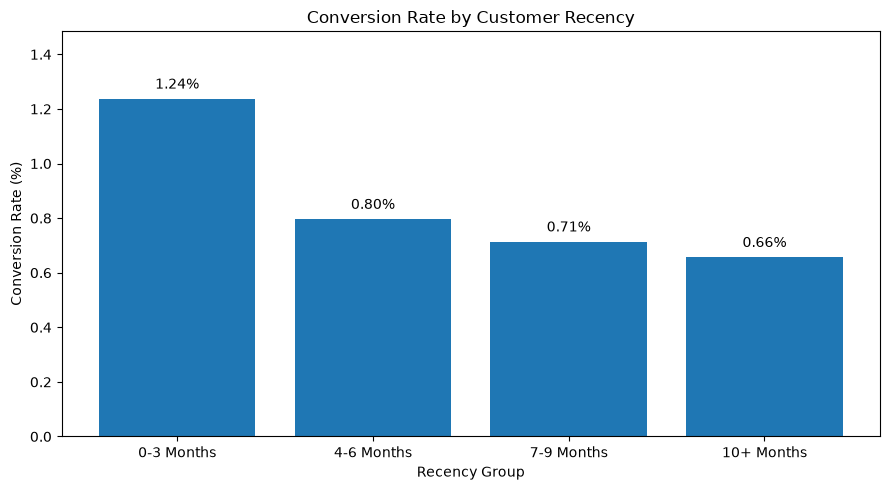

In [77]:
plt.figure(figsize=(9, 5))

bars = plt.bar(
    recency_kpi["recency_group"].astype(str),
    recency_kpi["conversion_rate"]
)

for bar in bars:
    height = bar.get_height()

    plt.annotate(
        f"{height:.2f}%",
        (
            bar.get_x() + bar.get_width() / 2,
            height
        ),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points"
    )

plt.title("Conversion Rate by Customer Recency")
plt.xlabel("Recency Group")
plt.ylabel("Conversion Rate (%)")
plt.ylim(0, recency_kpi["conversion_rate"].max() * 1.2)

plt.tight_layout()
plt.show()

Which recency group shows the strongest incremental response to the email campaign?

In [78]:
segment_performance = (
    df.groupby(
        ["recency_group", "segment"],
        observed=True
    )
    .agg(
        customers=("conversion", "size"),
        conversions=("conversion", "sum")
    )
    .reset_index()
)

segment_performance["conversion_rate"] = (
    segment_performance["conversions"] /
    segment_performance["customers"] * 100
)

display(segment_performance.round(2))

,recency_group,segment,customers,conversions,conversion_rate
0,0-3 Months,Mens E-Mail,7469,122,1.63
1,0-3 Months,No E-Mail,7438,67,0.90
2,0-3 Months,Womens E-Mail,7486,88,1.18
3,4-6 Months,Mens E-Mail,4673,49,1.05
4,4-6 Months,No E-Mail,4766,26,0.55
5,4-6 Months,Womens E-Mail,4753,38,0.80
6,7-9 Months,Mens E-Mail,4688,53,1.13
7,7-9 Months,No E-Mail,4699,16,0.34
8,7-9 Months,Womens E-Mail,4627,31,0.67
9,10+ Months,Mens E-Mail,4477,43,0.96


In [79]:
comparison = segment_performance.pivot(
    index="recency_group",
    columns="segment",
    values="conversion_rate"
)

comparison["Mens Lift (pp)"] = (
    comparison["Mens E-Mail"] -
    comparison["No E-Mail"]
)

comparison["Womens Lift (pp)"] = (
    comparison["Womens E-Mail"] -
    comparison["No E-Mail"]
)

display(comparison.round(2))

segment,Mens E-Mail,No E-Mail,Womens E-Mail,Mens Lift (pp),Womens Lift (pp)
recency_group,,,,,
0-3 Months,1.63,0.90,1.18,0.73,0.27
4-6 Months,1.05,0.55,0.80,0.50,0.25
7-9 Months,1.13,0.34,0.67,0.79,0.33
10+ Months,0.96,0.30,0.71,0.67,0.41


How does customer recency affect conversion rates and email campaign performance?

Thời gian kể từ lần mua gần nhất có mối liên hệ như thế nào với tỷ lệ chuyển đổi và hiệu quả chiến dịch email?
Chúng ta cần trả lời ba câu hỏi:
1. Nhóm khách hàng nào có Conversion Rate cao nhất?
2. Visit Rate và Revenue per Customer có khác nhau theo Recency không?
3. Nhóm nào có mức tăng Conversion Rate lớn nhất so với nhóm không nhận email?

In [80]:
print(df["history_segment"].value_counts().sort_index())

history_segment
1) $0 - $100        22970
2) $100 - $200      14254
3) $200 - $350      12289
4) $350 - $500       6409
5) $500 - $750       4911
6) $750 - $1,000     1859
7) $1,000 +          1308
Name: count, dtype: int64


In [81]:

def calculate_segment_kpi(df, dimension):
    result = (
        df.groupby([dimension, "segment"], observed=True)
        .agg(
            customers=("conversion", "size"),
            visitors=("visit", "sum"),
            conversions=("conversion", "sum"),
            total_spend=("spend", "sum")
        )
        .reset_index()
    )

    result["visit_rate"] = (
        result["visitors"] / result["customers"] * 100
    )

    result["conversion_rate"] = (
        result["conversions"] / result["customers"] * 100
    )

    result["revenue_per_customer"] = (
        result["total_spend"] / result["customers"]
    )

    return result


history_kpi = calculate_segment_kpi(
    df, "history_segment"
)

display(history_kpi.round(2))


,history_segment,segment,customers,visitors,conversions,total_spend,visit_rate,conversion_rate,revenue_per_customer
0,1) $0 - $100,Mens E-Mail,7724,1185,71,8150.18,15.34,0.92,1.06
1,1) $0 - $100,No E-Mail,7612,646,32,3934.59,8.49,0.42,0.52
2,1) $0 - $100,Womens E-Mail,7634,1005,61,8723.47,13.16,0.80,1.14
3,2) $100 - $200,Mens E-Mail,4691,751,42,5287.43,16.01,0.90,1.13
4,2) $100 - $200,No E-Mail,4836,440,20,2045.12,9.10,0.41,0.42
5,2) $100 - $200,Womens E-Mail,4727,631,37,4165.85,13.35,0.78,0.88
6,3) $200 - $350,Mens E-Mail,4090,862,63,6010.10,21.08,1.54,1.47
7,3) $200 - $350,No E-Mail,4044,511,28,3772.57,12.64,0.69,0.93
8,3) $200 - $350,Womens E-Mail,4155,675,26,2533.47,16.25,0.63,0.61
9,4) $350 - $500,Mens E-Mail,2097,502,42,5408.60,23.94,2.00,2.58


In [82]:

def calculate_lift(kpi, dimension):
    comparison = kpi.pivot(
        index=dimension,
        columns="segment",
        values="conversion_rate"
    )

    comparison["Mens Lift (pp)"] = (
        comparison["Mens E-Mail"]
        - comparison["No E-Mail"]
    )

    comparison["Womens Lift (pp)"] = (
        comparison["Womens E-Mail"]
        - comparison["No E-Mail"]
    )

    return comparison


history_lift = calculate_lift(
    history_kpi, "history_segment"
)

display(history_lift.round(2))


segment,Mens E-Mail,No E-Mail,Womens E-Mail,Mens Lift (pp),Womens Lift (pp)
history_segment,,,,,
1) $0 - $100,0.92,0.42,0.80,0.50,0.38
2) $100 - $200,0.90,0.41,0.78,0.48,0.37
3) $200 - $350,1.54,0.69,0.63,0.85,-0.07
4) $350 - $500,2.00,1.13,0.91,0.87,-0.22
5) $500 - $750,1.38,0.54,1.56,0.83,1.02
"6) $750 - $1,000",2.48,0.48,1.35,2.00,0.87
"7) $1,000 +",2.37,1.44,2.57,0.93,1.13


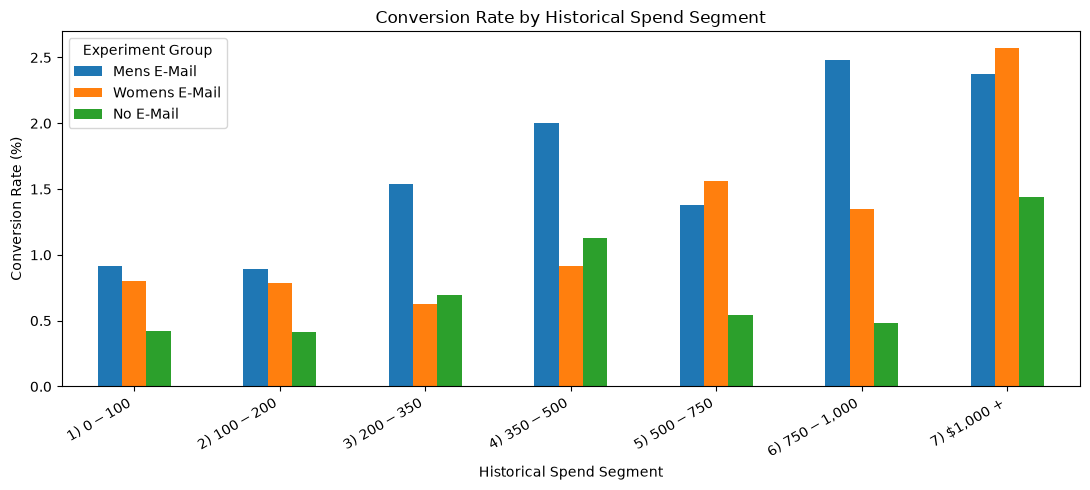

In [83]:


ax = history_lift[
    ["Mens E-Mail", "Womens E-Mail", "No E-Mail"]
].plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title("Conversion Rate by Historical Spend Segment")
plt.xlabel("Historical Spend Segment")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Experiment Group")
plt.tight_layout()
plt.show()

In [84]:
newbie_kpi = calculate_segment_kpi(
    df, "newbie"
)

display(newbie_kpi.round(2))

,newbie,segment,customers,visitors,conversions,total_spend,visit_rate,conversion_rate,revenue_per_customer
0,0,Mens E-Mail,10621,2247,148,16072.94,21.16,1.39,1.51
1,0,No E-Mail,10611,1419,82,9925.00,13.37,0.77,0.94
2,0,Womens E-Mail,10624,1847,92,11147.84,17.39,0.87,1.05
3,1,Mens E-Mail,10686,1647,119,14238.75,15.41,1.11,1.33
4,1,No E-Mail,10695,843,40,3983.33,7.88,0.37,0.37
5,1,Womens E-Mail,10763,1391,97,11890.27,12.92,0.90,1.10


In [85]:
newbie_lift = calculate_lift(
    newbie_kpi, "newbie"
)

display(newbie_lift.round(2))

segment,Mens E-Mail,No E-Mail,Womens E-Mail,Mens Lift (pp),Womens Lift (pp)
newbie,,,,,
0,1.39,0.77,0.87,0.62,0.09
1,1.11,0.37,0.90,0.74,0.53


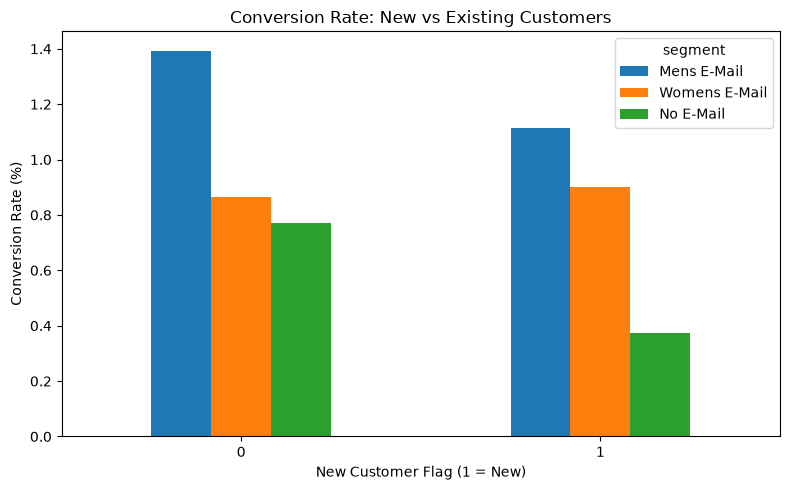

In [86]:
newbie_lift[
    ["Mens E-Mail", "Womens E-Mail", "No E-Mail"]
].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Conversion Rate: New vs Existing Customers")
plt.xlabel("New Customer Flag (1 = New)")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Customer by Channel

In [87]:
print(df["channel"].value_counts())

channel
Web             28217
Phone           28021
Multichannel     7762
Name: count, dtype: int64


In [88]:
channel_kpi = calculate_segment_kpi(
    df, "channel"
)

display(channel_kpi.round(2))

,channel,segment,customers,visitors,conversions,total_spend,visit_rate,conversion_rate,revenue_per_customer
0,Multichannel,Mens E-Mail,2577,545,44,4702.69,21.15,1.71,1.82
1,Multichannel,No E-Mail,2606,335,18,1604.62,12.85,0.69,0.62
2,Multichannel,Womens E-Mail,2579,453,36,4573.28,17.56,1.40,1.77
3,Phone,Mens E-Mail,9240,1504,100,11166.79,16.28,1.08,1.21
4,Phone,No E-Mail,9327,813,50,6010.81,8.72,0.54,0.64
5,Phone,Womens E-Mail,9454,1246,67,8290.46,13.18,0.71,0.88
6,Web,Mens E-Mail,9490,1845,123,14442.21,19.44,1.30,1.52
7,Web,No E-Mail,9373,1114,54,6292.90,11.89,0.58,0.67
8,Web,Womens E-Mail,9354,1539,86,10174.37,16.45,0.92,1.09


In [89]:
channel_lift = calculate_lift(
    channel_kpi, "channel"
)

display(channel_lift.round(2))

segment,Mens E-Mail,No E-Mail,Womens E-Mail,Mens Lift (pp),Womens Lift (pp)
channel,,,,,
Multichannel,1.71,0.69,1.40,1.02,0.71
Phone,1.08,0.54,0.71,0.55,0.17
Web,1.30,0.58,0.92,0.72,0.34


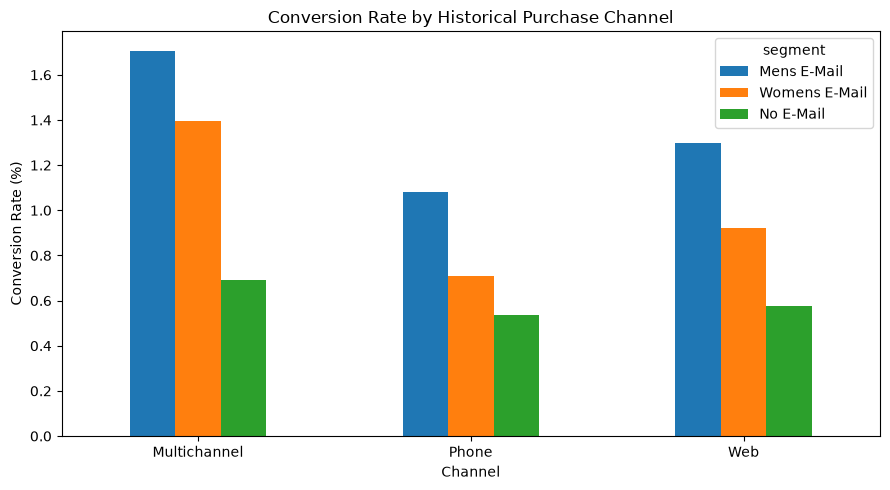

In [90]:
channel_lift[
    ["Mens E-Mail", "Womens E-Mail", "No E-Mail"]
].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Conversion Rate by Historical Purchase Channel")
plt.xlabel("Channel")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

A/B Testing & Statistical Significance

Did the Men's and Women's Email campaigns significantly increase conversion rates compared with the No Email control group?

Chúng ta có hai phép so sánh chính:
- Mens E-Mail vs No E-Mail
- Womens E-Mail vs No E-Mail
Không nên chỉ nhìn 1.25% lớn hơn 0.57% rồi kết luận chắc chắn chiến dịch có tác động. Cần xem độ bất định của chênh lệch.

In [91]:
# Create Experiment Summary table
experiment = (
    df.groupby("segment")
    .agg(
        customers=("conversion", "size"),
        conversions=("conversion", "sum")
    )
)

experiment["conversion_rate"] = (
    experiment["conversions"] /
    experiment["customers"]
)

display(experiment)

,customers,conversions,conversion_rate
segment,,,
Mens E-Mail,21307,267,0.012531
No E-Mail,21306,122,0.005726
Womens E-Mail,21387,189,0.008837


In [92]:

from statsmodels.stats.proportion import proportions_ztest

control = experiment.loc["No E-Mail"]

for group in ["Mens E-Mail", "Womens E-Mail"]:

    treatment = experiment.loc[group]

    counts = [
        treatment["conversions"],
        control["conversions"]
    ]

    nobs = [
        treatment["customers"],
        control["customers"]
    ]

    z_stat, p_value = proportions_ztest(
        count=counts,
        nobs=nobs,
        alternative="two-sided"
    )

    print(f"\n{group} vs No E-Mail")
    print(f"Z-statistic: {z_stat:.4f}")
    print(f"P-value: {p_value:.8f}")



Mens E-Mail vs No E-Mail
Z-statistic: 7.3851
P-value: 0.00000000

Womens E-Mail vs No E-Mail
Z-statistic: 3.7796
P-value: 0.00015711


In [93]:

from statsmodels.stats.proportion import confint_proportions_2indep

for group in ["Mens E-Mail", "Womens E-Mail"]:

    treatment = experiment.loc[group]
    control = experiment.loc["No E-Mail"]

    ci_low, ci_high = confint_proportions_2indep(
        count1=int(treatment["conversions"]),
        nobs1=int(treatment["customers"]),
        count2=int(control["conversions"]),
        nobs2=int(control["customers"]),
        compare="diff",
        method="newcomb",
        alpha=0.05
    )

    absolute_lift = (
        treatment["conversion_rate"]
        - control["conversion_rate"]
    )

    print(f"\n{group}")
    print(f"Absolute Lift: {absolute_lift * 100:.3f} pp")
    print(f"95% CI: [{ci_low * 100:.3f}, {ci_high * 100:.3f}] pp")



Mens E-Mail
Absolute Lift: 0.681 pp
95% CI: [0.501, 0.864] pp

Womens E-Mail
Absolute Lift: 0.311 pp
95% CI: [0.150, 0.475] pp


In [94]:
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportions_ztest

groups = ["Mens E-Mail", "Womens E-Mail"]

raw_p_values = []

for group in groups:
    t = experiment.loc[group]
    c = experiment.loc["No E-Mail"]

    _, p = proportions_ztest(
        [t["conversions"], c["conversions"]],
        [t["customers"], c["customers"]],
        alternative="two-sided"
    )

    raw_p_values.append(p)

reject, adjusted_p, _, _ = multipletests(
    raw_p_values,
    alpha=0.05,
    method="holm"
)

results = pd.DataFrame({
    "campaign": groups,
    "raw_p_value": raw_p_values,
    "adjusted_p_value": adjusted_p,
    "significant": reject
})

display(results)

,campaign,raw_p_value,adjusted_p_value,significant
0,Mens E-Mail,1.523224e-13,3.046447e-13,True
1,Womens E-Mail,1.571051e-04,1.571051e-04,True


Incrementality Analysis & Uplift Modeling

How many additional conversions and how much incremental revenue did our email campaigns generate?

In [95]:
# Incremental Conversions
# Campaign summary
incrementality = (
    df.groupby("segment")
    .agg(
        customers=("conversion", "size"),
        conversions=("conversion", "sum"),
        total_spend=("spend", "sum")
    )
)

# Conversion rate và revenue per customer
incrementality["conversion_rate"] = (
    incrementality["conversions"]
    / incrementality["customers"]
)

incrementality["revenue_per_customer"] = (
    incrementality["total_spend"]
    / incrementality["customers"]
)

# Control baseline
control_cvr = incrementality.loc[
    "No E-Mail", "conversion_rate"
]

# Absolute lift
incrementality["absolute_lift"] = (
    incrementality["conversion_rate"] - control_cvr
)

# Incremental conversions
incrementality["incremental_conversions"] = (
    incrementality["customers"]
    * incrementality["absolute_lift"]
)

display(incrementality.round(4))

,customers,conversions,total_spend,conversion_rate,revenue_per_customer,absolute_lift,incremental_conversions
segment,,,,,,,
Mens E-Mail,21307,267,30311.69,0.0125,1.4226,0.0068,144.9943
No E-Mail,21306,122,13908.33,0.0057,0.6528,0.0000,0.0000
Womens E-Mail,21387,189,23038.11,0.0088,1.0772,0.0031,66.5362


In [96]:
#Incremental Revenue
# How much additional revenue did each campaign generate compared with the control group?
# Control revenue per customer
control_rpc = incrementality.loc[
    "No E-Mail", "revenue_per_customer"
]

# Revenue lift per customer
incrementality["rpc_lift"] = (
    incrementality["revenue_per_customer"]
    - control_rpc
)

# Incremental revenue
incrementality["incremental_revenue"] = (
    incrementality["customers"]
    * incrementality["rpc_lift"]
)

# Display treatment groups
result = incrementality.loc[
    ["Mens E-Mail", "Womens E-Mail"],
    [
        "customers",
        "conversions",
        "conversion_rate",
        "absolute_lift",
        "incremental_conversions",
        "revenue_per_customer",
        "rpc_lift",
        "incremental_revenue"
    ]
]

display(result.round(4))

,customers,conversions,conversion_rate,absolute_lift,incremental_conversions,revenue_per_customer,rpc_lift,incremental_revenue
segment,,,,,,,,
Mens E-Mail,21307,267,0.0125,0.0068,144.9943,1.4226,0.7698,16402.7072
Womens E-Mail,21387,189,0.0088,0.0031,66.5362,1.0772,0.4244,9076.9041


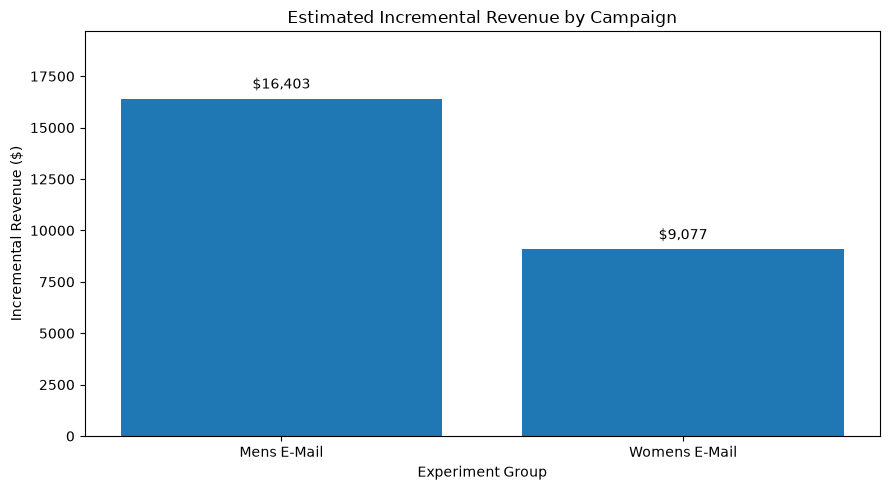

In [97]:
plot_data = result["incremental_revenue"]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    plot_data.index,
    plot_data.values
)

for bar in bars:
    height = bar.get_height()

    plt.annotate(
        f"${height:,.0f}",
        (
            bar.get_x() + bar.get_width() / 2,
            height
        ),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points"
    )

plt.title("Estimated Incremental Revenue by Campaign")
plt.ylabel("Incremental Revenue ($)")
plt.xlabel("Experiment Group")
plt.ylim(0, plot_data.max() * 1.2)

plt.tight_layout()
plt.show()

In [119]:
from pathlib import Path

# Nếu notebook nằm trong notebooks/
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

result.reset_index().to_csv(
    output_dir / "incrementality_summary.csv",
    index=False
)

print("Incrementality summary exported.")

Incrementality summary exported.


# Uplift Modeling bằng Machine Learning

In [98]:
ml_df = df[
    df["segment"].isin(["Mens E-Mail", "No E-Mail"])
].copy()

# Treatment indicator
ml_df["treatment"] = (
    ml_df["segment"] == "Mens E-Mail"
).astype(int)

features = [
    "recency",
    "history",
    "mens",
    "womens",
    "zip_code",
    "newbie",
    "channel"
]

target = "conversion"

print("Dataset shape:", ml_df.shape)
print(ml_df["treatment"].value_counts())
print(ml_df.groupby("treatment")[target].mean())


Dataset shape: (42613, 14)
treatment
1    21307
0    21306
Name: count, dtype: int64
treatment
0    0.005726
1    0.012531
Name: conversion, dtype: float64


In [99]:

from sklearn.model_selection import train_test_split

# Stratify by treatment and conversion outcome
strata = (
    ml_df["treatment"].astype(str)
    + "_"
    + ml_df["conversion"].astype(str)
)

train_df, test_df = train_test_split(
    ml_df,
    test_size=0.20,
    random_state=42,
    stratify=strata
)

print("Train:", train_df.shape)
print("Test:", test_df.shape)

print("\nTrain allocation:")
print(train_df["treatment"].value_counts())

print("\nTest allocation:")
print(test_df["treatment"].value_counts())


Train: (34090, 14)
Test: (8523, 14)

Train allocation:
treatment
0    17045
1    17045
Name: count, dtype: int64

Test allocation:
treatment
1    4262
0    4261
Name: count, dtype: int64


In [100]:

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

numeric_features = [
    "recency", "history", "mens", "womens", "newbie"
]

categorical_features = ["zip_code", "channel"]

def build_model():

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessing = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ])

    return Pipeline([
        ("preprocessing", preprocessing),
        ("model", LogisticRegression(max_iter=2000))
    ])


treatment_model = build_model()
control_model = build_model()

# Training data
treatment_train = train_df[train_df["treatment"] == 1]
control_train = train_df[train_df["treatment"] == 0]

# Fit separate models
treatment_model.fit(
    treatment_train[features],
    treatment_train[target]
)

control_model.fit(
    control_train[features],
    control_train[target]
)

print("Both models trained successfully!")


Both models trained successfully!


In [101]:

X_test = test_df[features]

# Predicted conversion probabilities
p_treatment = treatment_model.predict_proba(X_test)[:, 1]
p_control = control_model.predict_proba(X_test)[:, 1]

# Predicted uplift
predicted_uplift = p_treatment - p_control

uplift_results = test_df[
    ["treatment", "conversion"]
].copy()

uplift_results["p_treatment"] = p_treatment
uplift_results["p_control"] = p_control
uplift_results["predicted_uplift"] = predicted_uplift

display(uplift_results.head(10).round(4))


,treatment,conversion,p_treatment,p_control,predicted_uplift
51594,1,0,0.0094,0.0029,0.0065
25714,1,0,0.0083,0.0026,0.0058
3017,1,0,0.0257,0.0085,0.0172
36001,0,0,0.0070,0.0019,0.0051
21347,0,0,0.0196,0.0084,0.0112
51055,1,0,0.0115,0.0034,0.0081
16410,1,0,0.0129,0.0053,0.0076
62585,0,0,0.0149,0.0136,0.0013
11425,0,0,0.0081,0.0024,0.0057
10209,0,0,0.0157,0.0147,0.0010


In [102]:

# Assign customers to 3 uplift groups
uplift_results["uplift_group"] = pd.qcut(
    uplift_results["predicted_uplift"].rank(method="first"),
    q=3,
    labels=["Low", "Medium", "High"]
)

# Observed conversion rate by uplift group
uplift_evaluation = (
    uplift_results.groupby(
        ["uplift_group", "treatment"],
        observed=True
    )
    .agg(
        customers=("conversion", "size"),
        conversions=("conversion", "sum")
    )
    .reset_index()
)

uplift_evaluation["conversion_rate"] = (
    uplift_evaluation["conversions"]
    / uplift_evaluation["customers"]
)

display(uplift_evaluation.round(4))


,uplift_group,treatment,customers,conversions,conversion_rate
0,Low,0,1399,9,0.0064
1,Low,1,1442,19,0.0132
2,Medium,0,1419,11,0.0078
3,Medium,1,1422,11,0.0077
4,High,0,1443,4,0.0028
5,High,1,1398,24,0.0172


In [103]:

# Caculate Observed Uplift in test set
evaluation = uplift_evaluation.pivot(
    index="uplift_group",
    columns="treatment",
    values="conversion_rate"
)

evaluation = evaluation.rename(columns={
    0: "Control CVR",
    1: "Treatment CVR"
})

evaluation["Observed Lift (pp)"] = (
    evaluation["Treatment CVR"]
    - evaluation["Control CVR"]
) * 100

display(evaluation.round(3))


treatment,Control CVR,Treatment CVR,Observed Lift (pp)
uplift_group,,,
Low,0.006,0.013,0.674
Medium,0.008,0.008,-0.002
High,0.003,0.017,1.440


In [104]:

from statsmodels.stats.proportion import confint_proportions_2indep
import pandas as pd

results = []

for group in ["Low", "Medium", "High"]:

    subset = uplift_evaluation[
        uplift_evaluation["uplift_group"] == group
    ]

    t = subset[subset["treatment"] == 1].iloc[0]
    c = subset[subset["treatment"] == 0].iloc[0]

    lift = (
        t["conversions"] / t["customers"]
        - c["conversions"] / c["customers"]
    )

    ci_low, ci_high = confint_proportions_2indep(
        count1=int(t["conversions"]),
        nobs1=int(t["customers"]),
        count2=int(c["conversions"]),
        nobs2=int(c["customers"]),
        compare="diff",
        method="newcomb",
        alpha=0.05
    )

    results.append({
        "uplift_group": group,
        "observed_lift_pp": lift * 100,
        "ci_low_pp": ci_low * 100,
        "ci_high_pp": ci_high * 100
    })

uplift_ci = pd.DataFrame(results)

display(uplift_ci.round(3))


,uplift_group,observed_lift_pp,ci_low_pp,ci_high_pp
0,Low,0.674,-0.070,1.466
1,Medium,-0.002,-0.698,0.694
2,High,1.440,0.731,2.282


In [105]:

from statsmodels.stats.proportion import confint_proportions_2indep

results = []

for group in ["Low", "Medium", "High"]:

    subset = uplift_evaluation[
        uplift_evaluation["uplift_group"] == group
    ]

    t = subset[subset["treatment"] == 1].iloc[0]
    c = subset[subset["treatment"] == 0].iloc[0]

    lift = (
        t["conversions"] / t["customers"]
        - c["conversions"] / c["customers"]
    )

    ci_low, ci_high = confint_proportions_2indep(
        count1=int(t["conversions"]),
        nobs1=int(t["customers"]),
        count2=int(c["conversions"]),
        nobs2=int(c["customers"]),
        compare="diff",
        method="newcomb",
        alpha=0.05
    )

    results.append({
        "uplift_group": group,
        "observed_lift_pp": lift * 100,
        "ci_low_pp": ci_low * 100,
        "ci_high_pp": ci_high * 100
    })

uplift_ci = pd.DataFrame(results)

display(uplift_ci.round(3))


,uplift_group,observed_lift_pp,ci_low_pp,ci_high_pp
0,Low,0.674,-0.070,1.466
1,Medium,-0.002,-0.698,0.694
2,High,1.440,0.731,2.282


Can our uplift model identify customers with higher incremental response than random targeting?

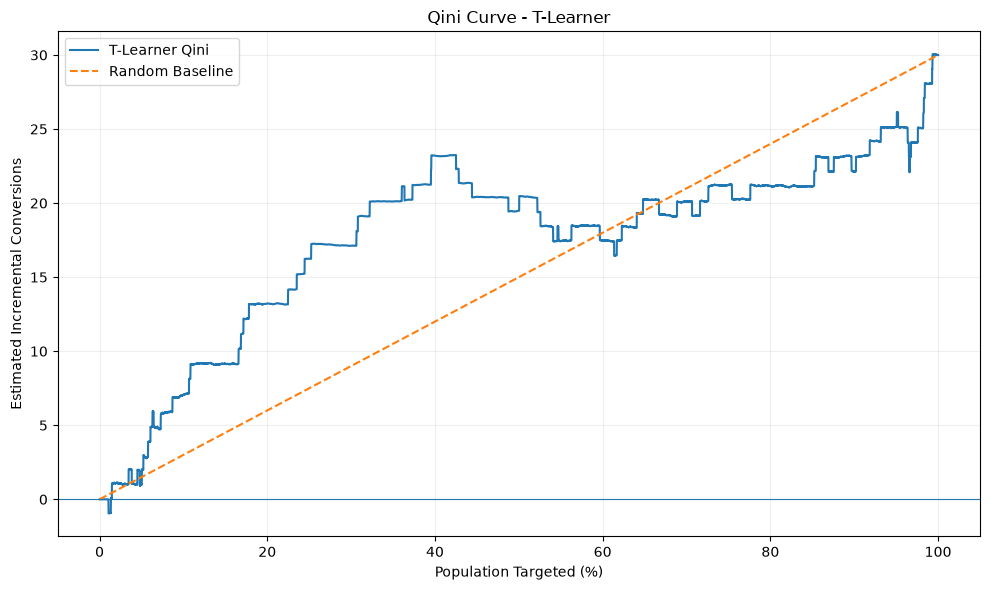

In [106]:

import numpy as np

# 1. Sort by predicted uplift
qini_df = uplift_results.sort_values(
    "predicted_uplift",
    ascending=False
).copy()

# 2. Separate treatment and control outcomes
qini_df["t_count"] = qini_df["treatment"]
qini_df["c_count"] = 1 - qini_df["treatment"]

qini_df["t_conv"] = (
    qini_df["treatment"] * qini_df["conversion"]
)
qini_df["c_conv"] = (
    qini_df["c_count"] * qini_df["conversion"]
)

# 3. Cumulative statistics
for col in ["t_count", "c_count", "t_conv", "c_conv"]:
    qini_df["cum_" + col] = qini_df[col].cumsum()

# 4. Cumulative incremental conversions
qini_df["qini"] = (
    qini_df["cum_t_conv"]
    - qini_df["cum_c_conv"]
    * qini_df["cum_t_count"]
    / qini_df["cum_c_count"].replace(0, np.nan)
)

# 5. Population fraction
qini_df["population_pct"] = (
    np.arange(1, len(qini_df) + 1) / len(qini_df)
)

# 6. Random-targeting reference
final_qini = qini_df["qini"].iloc[-1]

qini_df["random_baseline"] = (
    qini_df["population_pct"] * final_qini
)

# 7. Add origin
curve = pd.concat([
    pd.DataFrame({
        "population_pct": [0.0],
        "qini": [0.0],
        "random_baseline": [0.0]
    }),
    qini_df[
        ["population_pct", "qini", "random_baseline"]
    ]
], ignore_index=True)

# 8. Visualization
plt.figure(figsize=(10, 6))

plt.plot(
    curve["population_pct"] * 100,
    curve["qini"],
    label="T-Learner Qini"
)

plt.plot(
    curve["population_pct"] * 100,
    curve["random_baseline"],
    linestyle="--",
    label="Random Baseline"
)

plt.axhline(0, linewidth=0.8)

plt.title("Qini Curve - T-Learner")
plt.xlabel("Population Targeted (%)")
plt.ylabel("Estimated Incremental Conversions")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [107]:
valid_curve = curve.dropna(
    subset=["qini", "random_baseline"]
).sort_values("population_pct")

qini_coefficient = np.trapezoid(
    valid_curve["qini"] - valid_curve["random_baseline"],
    valid_curve["population_pct"]
)

print("Qini coefficient:", round(qini_coefficient, 4))

Qini coefficient: 2.5543


T-Learner – Model Evaluation
Objective: Estimate heterogeneous treatment effects of the Men's Email campaign.
Method: T-Learner using Logistic Regression, evaluated on a held-out test set of 8,523 customers.
Results: The model achieved a Qini coefficient of +2.5543. The high predicted-uplift group recorded an observed conversion lift of +1.44 percentage points, with a 95% confidence interval of +0.731 to +2.282 percentage points.
Limitation: The uplift ranking was not consistently monotonic across customer groups, and the Qini coefficient has not been validated for statistical uncertainty.
Recommendation: Assess ranking stability and validate performance on independent data before deployment.

In [108]:
for pct in [0.20, 0.40, 0.60, 0.80, 1.00]:
    row = valid_curve.iloc[
        (valid_curve["population_pct"] - pct)
        .abs()
        .argmin()
    ]

    print(
        f"Top {pct:.0%}: "
        f"Model={row['qini']:.2f}, "
        f"Random={row['random_baseline']:.2f}, "
        f"Gain={row['qini'] - row['random_baseline']:.2f}"
    )

Top 20%: Model=13.22, Random=6.00, Gain=7.22
Top 40%: Model=23.20, Random=12.00, Gain=11.21
Top 60%: Model=17.47, Random=18.00, Gain=-0.52
Top 80%: Model=21.16, Random=23.99, Gain=-2.84
Top 100%: Model=29.99, Random=29.99, Gain=0.00


In [109]:
from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Kết quả dự đoán trên tập test
uplift_results.to_csv(
    output_dir / "uplift_predictions.csv",
    index=False
)

# Kết quả observed uplift và CI
uplift_ci.to_csv(
    output_dir / "uplift_evaluation.csv",
    index=False
)

print("Model evaluation files exported!")

Model evaluation files exported!


In [110]:


# Nếu notebook chạy từ thư mục notebooks/, đổi thành ../data/processed
output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Customer-level experiment
customer_export = df.copy()

# Technical row identifier
customer_export.insert(
    0,
    "customer_row_id",
    range(1, len(customer_export) + 1)
)

customer_export.to_csv(
    output_dir / "customer_experiment.csv",
    index=False
)

# 2. Campaign KPIs
campaign_kpi.to_csv(
    output_dir / "campaign_kpi.csv",
    index=False
)

# 3. Customer segmentation KPIs
for name, table in {
    "recency_kpi": recency_kpi,
    "history_kpi": history_kpi,
    "newbie_kpi": newbie_kpi,
    "channel_kpi": channel_kpi
}.items():
    table.to_csv(
        output_dir / f"{name}.csv",
        index=False
    )

print("Customer and KPI exports completed.")


Customer and KPI exports completed.


In [111]:

from statsmodels.stats.proportion import (
    proportions_ztest,
    confint_proportions_2indep
)
from statsmodels.stats.multitest import multipletests

experiment_summary = (
    df.groupby("segment")
    .agg(
        customers=("conversion", "size"),
        conversions=("conversion", "sum"),
        total_spend=("spend", "sum")
    )
)

experiment_summary["cvr"] = (
    experiment_summary["conversions"]
    / experiment_summary["customers"]
)

experiment_summary["rpc"] = (
    experiment_summary["total_spend"]
    / experiment_summary["customers"]
)

control = experiment_summary.loc["No E-Mail"]
records = []

for group in ["Mens E-Mail", "Womens E-Mail"]:
    t = experiment_summary.loc[group]

    z, p = proportions_ztest(
        [int(t["conversions"]), int(control["conversions"])],
        [int(t["customers"]), int(control["customers"])]
    )

    lo, hi = confint_proportions_2indep(
        int(t["conversions"]), int(t["customers"]),
        int(control["conversions"]), int(control["customers"]),
        compare="diff",
        method="newcomb"
    )

    records.append({
        "campaign": group,
        "control": "No E-Mail",
        "absolute_lift_pp": (t["cvr"] - control["cvr"]) * 100,
        "incremental_conversions": (
            t["customers"] * (t["cvr"] - control["cvr"])
        ),
        "incremental_revenue": (
            t["customers"] * (t["rpc"] - control["rpc"])
        ),
        "raw_p_value": p,
        "ci_low_pp": lo * 100,
        "ci_high_pp": hi * 100
    })

experiment_statistics = pd.DataFrame(records)

_, adjusted_p, _, _ = multipletests(
    experiment_statistics["raw_p_value"],
    method="holm"
)

experiment_statistics["adjusted_p_value"] = adjusted_p
experiment_statistics["significant"] = adjusted_p < 0.05

experiment_statistics.to_csv(
    output_dir / "experiment_statistics.csv",
    index=False
)

display(experiment_statistics.round(4))


,campaign,control,absolute_lift_pp,incremental_conversions,incremental_revenue,raw_p_value,ci_low_pp,ci_high_pp,adjusted_p_value,significant
0,Mens E-Mail,No E-Mail,0.6805,144.9943,16402.7072,0.0000,0.5014,0.8641,0.0000,True
1,Womens E-Mail,No E-Mail,0.3111,66.5362,9076.9041,0.0002,0.1502,0.4745,0.0002,True


In [112]:
uplift_results.to_csv(
    output_dir / "uplift_test.csv",
    index=False
)

uplift_ci.to_csv(
    output_dir / "uplift_evaluation.csv",
    index=False
)

curve.to_csv(
    output_dir / "qini_curve.csv",
    index=False
)

print("Uplift model exports completed.")

Uplift model exports completed.


In [113]:
for file in sorted(output_dir.glob("*.csv")):
    table = pd.read_csv(file)

    print(
        f"{file.name:35s}"
        f"{table.shape[0]:>8,} rows | "
        f"{table.shape[1]:>3} columns"
    )

campaign_kpi.csv                          3 rows |   9 columns
channel_kpi.csv                           9 rows |   9 columns
customer_experiment.csv              64,000 rows |  14 columns
experiment_statistics.csv                 2 rows |  10 columns
history_kpi.csv                          21 rows |   9 columns
newbie_kpi.csv                            6 rows |   9 columns
qini_curve.csv                        8,524 rows |   3 columns
recency_kpi.csv                           4 rows |   8 columns
uplift_evaluation.csv                     3 rows |   4 columns
uplift_test.csv                       8,523 rows |   6 columns


In [116]:
# Verify original indexing
print(df.index.equals(pd.RangeIndex(len(df))))

# Preserve matching IDs
uplift_export = uplift_results.copy()

uplift_export.insert(
    0,
    "customer_row_id",
    uplift_export.index + 1
)

uplift_export.to_csv(
    output_dir / "uplift_test.csv",
    index=False
)

print("Unique uplift IDs:", uplift_export["customer_row_id"].nunique())
print("Test rows:", len(uplift_export))

True
Unique uplift IDs: 8523
Test rows: 8523


In [117]:
recency_campaign_kpi = calculate_segment_kpi(
    df,
    "recency_group"
)

recency_campaign_kpi.to_csv(
    output_dir / "recency_campaign_kpi.csv",
    index=False
)

print(recency_campaign_kpi.shape)

(12, 9)


In [118]:
customer_ids = set(customer_export["customer_row_id"])
uplift_ids = set(uplift_export["customer_row_id"])

print("All uplift IDs match:", uplift_ids.issubset(customer_ids))
print("Duplicate customer IDs:",
      customer_export["customer_row_id"].duplicated().sum())
print("Duplicate uplift IDs:",
      uplift_export["customer_row_id"].duplicated().sum())

All uplift IDs match: True
Duplicate customer IDs: 0
Duplicate uplift IDs: 0
